# Oasis Infobyte Internship — Data Science Task 4
## Email Spam Detection with Machine Learning

**Objective:** Train NLP classifiers to distinguish spam (`spam`) from legitimate messages (`ham`).

In [27]:
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

In [28]:
# Set this to your exact file name, for example "spam.csv" or "SMSSpamCollection".
# Leave as None to search for common file names in the current folder.
DATA_PATH = None

if DATA_PATH is None:
    candidates = ["spam.csv", "SMSSpamCollection", "SMSSpamCollection.txt", "spam.tsv"]
    existing = [name for name in candidates if Path(name).exists()]
    if not existing:
        raise FileNotFoundError(
            "Dataset file not found. Download/extract the SMS Spam Collection dataset, "
            "put spam.csv or SMSSpamCollection beside this notebook, and set DATA_PATH."
        )
    DATA_PATH = existing[0]

path = Path(DATA_PATH)
if not path.exists():
    raise FileNotFoundError(f"Could not find {path.resolve()}. Check DATA_PATH.")

# Kaggle copies are generally CSV. UCI's original file is tab-separated without headers.
if path.suffix.lower() == ".csv":
    raw = pd.read_csv(path, encoding="latin-1")
else:
    raw = pd.read_csv(
        path,
        sep="\t",
        header=None,
        names=["label", "message"],
        encoding="utf-8",
        on_bad_lines="skip",
    )

print("File:", path.name)
print("Raw shape:", raw.shape)
print("Columns:", raw.columns.tolist())
raw.head()

File: SMSSpamCollection
Raw shape: (5572, 2)
Columns: ['label', 'message']


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [29]:
def normalize_column_name(name):
    return re.sub(r"\s+", "", str(name).strip().lower())

normalized_columns = {normalize_column_name(col): col for col in raw.columns}
label_candidates = ["label", "category", "class", "type", "target", "v1"]
text_candidates = ["message", "text", "sms", "email", "body", "content", "v2"]

label_col = next((normalized_columns[c] for c in label_candidates if c in normalized_columns), None)
text_col = next((normalized_columns[c] for c in text_candidates if c in normalized_columns), None)

# Fallback for simple two-column datasets whose headers use unexpected names.
if label_col is None or text_col is None:
    if raw.shape[1] >= 2:
        label_col, text_col = raw.columns[0], raw.columns[1]
    else:
        raise ValueError("Could not identify label and message columns. Inspect raw.head() and set the columns manually.")

df = raw[[label_col, text_col]].copy()
df.columns = ["label", "message"]
df = df.dropna(subset=["label", "message"])
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

label_map = {
    "ham": "ham", "legitimate": "ham", "legit": "ham", "not spam": "ham",
    "not_spam": "ham", "non-spam": "ham", "nonspam": "ham", "normal": "ham",
    "0": "ham", "false": "ham",
    "spam": "spam", "junk": "spam", "1": "spam", "true": "spam",
}
df["label"] = df["label"].map(label_map)
df = df.dropna(subset=["label"])
df = df[df["message"].str.len() > 0]
df = df.drop_duplicates(subset=["label", "message"]).reset_index(drop=True)

if df["label"].nunique() != 2:
    raise ValueError(
        "Expected two classes that can be mapped to 'ham' and 'spam'. "
        "Inspect df['label'].value_counts() and adjust label_map if your dataset uses different labels."
    )

print("Cleaned shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows remaining:", df.duplicated().sum())
df.head()

Cleaned shape: (5158, 2)
Missing values:
 label      0
message    0
dtype: int64
Duplicate rows remaining: 0


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


,Count,Percentage (%)
label,,
ham,4516,87.55
spam,642,12.45


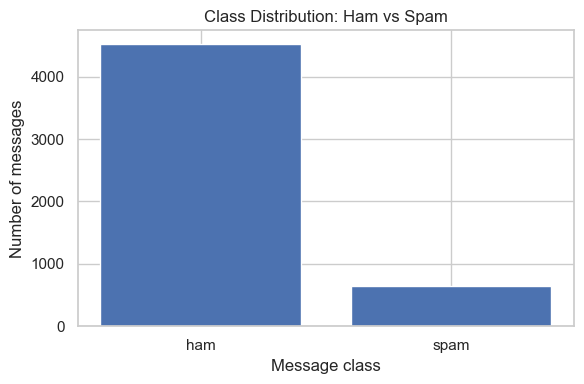

In [30]:
class_counts = df["label"].value_counts().reindex(["ham", "spam"], fill_value=0)
class_percentages = (class_counts / class_counts.sum() * 100).round(2)
class_summary = pd.DataFrame({"Count": class_counts, "Percentage (%)": class_percentages})
display(class_summary)

plt.figure(figsize=(6, 4))
plt.bar(class_summary.index.astype(str), class_summary["Count"].values)
plt.title("Class Distribution: Ham vs Spam")
plt.xlabel("Message class")
plt.ylabel("Number of messages")
plt.tight_layout()
plt.show()

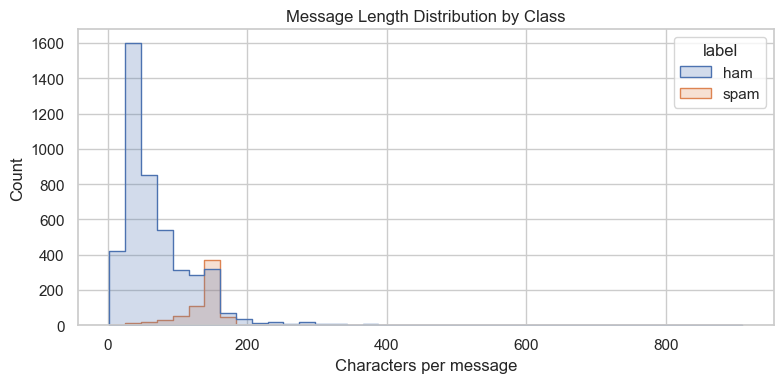

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4516.0,70.9,56.7,2.0,34.0,53.0,91.0,910.0
spam,642.0,137.4,30.0,13.0,131.0,148.0,157.0,223.0


In [31]:
# Compare message lengths by class. This is exploratory, not a model feature used directly.
df["message_length"] = df["message"].str.len()
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="message_length", hue="label", bins=40, element="step", stat="count", common_norm=False)
plt.title("Message Length Distribution by Class")
plt.xlabel("Characters per message")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

display(df.groupby("label")["message_length"].describe().round(1))

In [32]:
def clean_text(text):
    """Normalize message text before TF-IDF tokenization."""
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " urltoken ", text)
    text = re.sub(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b", " emailtoken ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

example = df["message"].iloc[0]
print("Original:", example)
print("Cleaned: ", clean_text(example))

Original: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Cleaned:  go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat


In [33]:
X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training messages:", len(X_train))
print("Testing messages: ", len(X_test))
print("Training class proportions:\n", y_train.value_counts(normalize=True).round(3))
print("Testing class proportions:\n", y_test.value_counts(normalize=True).round(3))

Training messages: 4126
Testing messages:  1032
Training class proportions:
 label
ham     0.875
spam    0.125
Name: proportion, dtype: float64
Testing class proportions:
 label
ham     0.876
spam    0.124
Name: proportion, dtype: float64


In [34]:
def make_tfidf():
    return TfidfVectorizer(
        preprocessor=clean_text,
        stop_words="english",
        ngram_range=(1, 2),
        max_features=30000,
        min_df=1,
    )

models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", make_tfidf()),
        ("classifier", MultinomialNB()),
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", make_tfidf()),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
}

trained_models = {}
result_rows = []

for model_name, model in models.items():
    print("\n" + "=" * 70)
    print(model_name)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    trained_models[model_name] = model

    result_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Spam Precision": precision_score(y_test, predictions, pos_label="spam", zero_division=0),
        "Spam Recall": recall_score(y_test, predictions, pos_label="spam", zero_division=0),
        "Spam F1-score": f1_score(y_test, predictions, pos_label="spam", zero_division=0),
        "Macro F1-score": f1_score(y_test, predictions, average="macro", zero_division=0),
    })

    print(classification_report(
        y_test,
        predictions,
        labels=["ham", "spam"],
        target_names=["Ham (legitimate)", "Spam"],
        zero_division=0,
    ))

results_df = pd.DataFrame(result_rows).sort_values("Spam F1-score", ascending=False).reset_index(drop=True)
display(results_df.round(4))


Multinomial Naive Bayes
                  precision    recall  f1-score   support

Ham (legitimate)       0.95      1.00      0.98       904
            Spam       1.00      0.64      0.78       128

        accuracy                           0.96      1032
       macro avg       0.98      0.82      0.88      1032
    weighted avg       0.96      0.96      0.95      1032


Logistic Regression
                  precision    recall  f1-score   support

Ham (legitimate)       0.99      0.99      0.99       904
            Spam       0.91      0.92      0.91       128

        accuracy                           0.98      1032
       macro avg       0.95      0.95      0.95      1032
    weighted avg       0.98      0.98      0.98      1032



,Model,Accuracy,Spam Precision,Spam Recall,Spam F1-score,Macro F1-score
0,Logistic Regression,0.9787,0.9077,0.9219,0.9147,0.9513
1,Multinomial Naive Bayes,0.9554,1.0000,0.6406,0.7810,0.8781


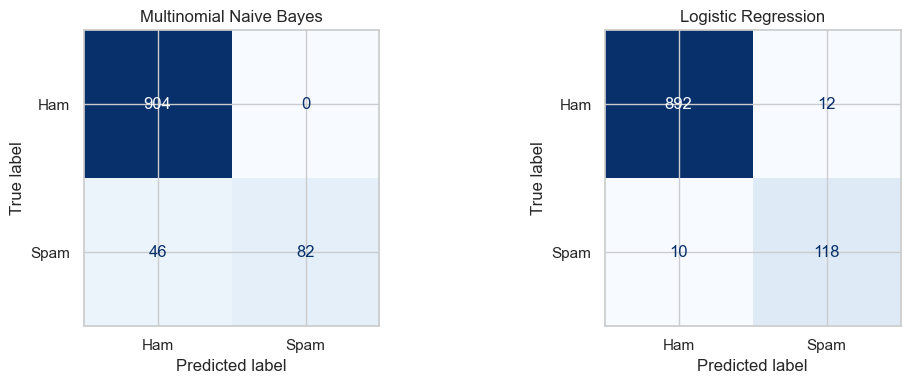

In [35]:
fig, axes = plt.subplots(1, len(trained_models), figsize=(11, 4))
if len(trained_models) == 1:
    axes = [axes]

for ax, (model_name, model) in zip(axes, trained_models.items()):
    predictions = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=["ham", "spam"],
        display_labels=["Ham", "Spam"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(model_name)

plt.tight_layout()
plt.show()

In [36]:
best_name = results_df.loc[0, "Model"]
best_model = trained_models[best_name]
best_row = results_df.iloc[0]

print("Selected model:", best_name)
print(f"Accuracy:      {best_row['Accuracy']:.4f}")
print(f"Spam precision:{best_row['Spam Precision']:.4f}")
print(f"Spam recall:   {best_row['Spam Recall']:.4f}")
print(f"Spam F1-score: {best_row['Spam F1-score']:.4f}")
print("\nDecision: selected by Spam F1-score. Use the metric table and confusion matrix in your findings.")

Selected model: Logistic Regression
Accuracy:      0.9787
Spam precision:0.9077
Spam recall:   0.9219
Spam F1-score: 0.9147

Decision: selected by Spam F1-score. Use the metric table and confusion matrix in your findings.


In [37]:
sample_messages = [
    "Congratulations! You have won a free prize. Click the link now to claim your reward.",
    "Hi, are we still meeting at the library at 4 pm today?",
    "URGENT! Your account has been selected for a cash reward. Reply now.",
    "Please send me the notes from today's lecture when you get time.",
]

for message in sample_messages:
    prediction = best_model.predict([message])[0]
    print(f"Prediction: {prediction.upper():4} | Message: {message}")

Prediction: SPAM | Message: Congratulations! You have won a free prize. Click the link now to claim your reward.
Prediction: HAM  | Message: Hi, are we still meeting at the library at 4 pm today?
Prediction: SPAM | Message: URGENT! Your account has been selected for a cash reward. Reply now.
Prediction: HAM  | Message: Please send me the notes from today's lecture when you get time.


In [38]:
try:
    from wordcloud import WordCloud
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

    for label in ["spam", "ham"]:
        joined_text = " ".join(df.loc[df["label"] == label, "message"].astype(str))
        cloud = WordCloud(width=900, height=450, background_color="white", stopwords=set(ENGLISH_STOP_WORDS)).generate(joined_text)
        plt.figure(figsize=(10, 5))
        plt.imshow(cloud, interpolation="bilinear")
        plt.axis("off")
        plt.title(f"Common words in {label.upper()} messages")
        plt.show()
except ImportError:
    print("Optional package missing. Run %pip install wordcloud, then rerun this cell.")

Optional package missing. Run %pip install wordcloud, then rerun this cell.


# Email Spam Detection with Machine Learning — Final Findings

## 1. Dataset Overview

The project used the SMS Spam Collection dataset to classify messages as spam or legitimate (ham). The original dataset contained **5,572 records**. After data cleaning and duplicate removal, **5,158 messages** remained for analysis.

The final dataset contained:

- **Ham messages:** 4,516 (87.55%)
- **Spam messages:** 642 (12.45%)

This shows a clear class imbalance, with legitimate messages accounting for the majority of the dataset.

## 2. Data Exploration and Preprocessing

Exploratory Data Analysis was performed to examine the class distribution and message lengths. The analysis showed that spam messages were generally longer than legitimate messages in this dataset.

Text preprocessing included converting messages to lowercase, normalizing URLs and email addresses, removing punctuation, and cleaning extra whitespace. English stopwords were filtered during feature extraction.

TF-IDF (Term Frequency–Inverse Document Frequency) was used to convert text messages into numerical features. Both individual words and two-word phrases were considered to capture useful textual patterns.

## 3. Model Training

The dataset was divided into training and testing sets using an 80:20 split, with stratification to preserve class proportions. A total of 4,126 messages were used for training and 1,032 for testing.

Two classification algorithms were evaluated:

1. **Multinomial Naive Bayes**
2. **Logistic Regression**

Both models were implemented using scikit-learn pipelines combining TF-IDF vectorization and classification.

## 4. Model Evaluation

The models were evaluated using accuracy, spam precision, spam recall, spam F1-score, and confusion matrices.

| Evaluation metric | Multinomial Naive Bayes | Logistic Regression |
|---|---:|---:|
| Accuracy | 95.54% | 97.87% |
| Spam precision | 100.00% | 90.77% |
| Spam recall | 64.06% | 92.19% |
| Spam F1-score | 78.10% | 91.47% |
| Macro F1-score | 87.81% | 95.13% |

Logistic Regression achieved better overall performance, with an accuracy of 97.87% and a spam F1-score of 91.47%. It also identified a substantially greater proportion of actual spam messages.

Multinomial Naive Bayes achieved 100% spam precision, meaning that none of its spam predictions in the test set were false positives. However, its spam recall was only 64.06%, indicating that it missed a considerable proportion of actual spam messages.

## 5. Confusion Matrix Analysis

On the 1,032-message test set:

- **Logistic Regression** correctly classified 892 legitimate messages and 118 spam messages. It incorrectly classified 12 legitimate messages as spam and missed 10 spam messages.
- **Multinomial Naive Bayes** correctly classified 904 legitimate messages and 82 spam messages. It incorrectly flagged zero legitimate messages as spam but missed 46 spam messages.

These results demonstrate the trade-off between precision and recall. For spam detection, recall is particularly important because missed spam messages may reach the user's inbox. Precision is also important to avoid incorrectly flagging legitimate messages.

## 6. Final Conclusion

Logistic Regression was selected as the best-performing model based on its spam F1-score. Its 97.87% accuracy, 92.19% spam recall, and 91.47% spam F1-score make it the stronger choice between the two evaluated classifiers for this dataset.

The project demonstrates how Natural Language Processing, TF-IDF feature extraction, and supervised machine learning can be combined to classify unwanted messages. Further improvements could include evaluating additional classifiers, tuning decision thresholds, and testing the model on a separate dataset containing full-length emails.

**Note:** The project used an SMS spam dataset, as recommended by the internship task sheet. Therefore, the results demonstrate SMS spam classification rather than direct validation on full-length email messages.